# Dataset 3 - Fake Internship Detection

In [14]:
# Imports & Dataset Loading
import os
import pandas as pd
import numpy as np

# Read Dataset 3 from Datasets folder
if os.path.exists("../Datasets/Dataset3.csv"):
    df = pd.read_csv("../Datasets/Dataset3.csv")
else:
    df = pd.read_csv("../Datasets/fake_internship_detection_dataset.csv")
    # Save a clean copy as Dataset3.csv
    df.to_csv("../Datasets/Dataset3.csv", index=False)

In [15]:
# Exploratory Data Analysis (EDA)

# Display first 5 rows
df.head()

,posting_date,internship_title,employment_type,work_mode,industry,location,company_name,company_size,company_age,linkedin_presence,...,recruiter_experience_years,recruiter_email_type,suspicious_email_domain,recruiter_response_time_hours,social_media_presence,emotional_manipulation_score,phishing_language_score,trust_signal_score,fraud_score,is_fake_posting
0,2026-09-10,ML Engineer,Internship,Remote,Marketing,Berlin,"Russell, Medina and Evans",Startup,23.0,1,...,0.3,Free,1,17.6,1,12,28,48.4,51.8,1
1,2020-05-10,UI/UX Designer,Contract,Onsite,Marketing,Bangalore,Hays-White,Startup,12.0,0,...,5.1,Free,1,30.2,1,9,27,47.6,75.3,1
2,2021-07-18,UI/UX Designer,Internship,Hybrid,Gaming,Toronto,"Obrien, Gonzalez and Harris",Small,10.0,1,...,6.0,Free,1,12.5,0,26,18,98.8,0.0,0
3,2021-02-04,UI/UX Designer,Part-Time,Remote,AI,Berlin,"Martinez, Odonnell and Davidson",Enterprise,33.0,1,...,3.8,Corporate,0,24.6,1,20,0,72.2,11.0,0
4,2020-12-31,AI Research Intern,Internship,Onsite,EdTech,Toronto,Garcia-Owens,Small,14.0,0,...,7.0,Free,1,30.3,0,16,50,34.4,56.0,1


In [16]:
# Dataset Size & Dimensions

# Check total rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (1000000, 33)


In [17]:
# Column Names

# Check all available features
print("Columns in Dataset 3:\n", df.columns.tolist())

Columns in Dataset 3:
 ['posting_date', 'internship_title', 'employment_type', 'work_mode', 'industry', 'location', 'company_name', 'company_size', 'company_age', 'linkedin_presence', 'website_available', 'domain_age_months', 'verification_status', 'stipend', 'unrealistic_salary_flag', 'payment_required', 'registration_fee', 'job_description_length', 'grammatical_errors', 'vague_description_score', 'urgency_score', 'keyword_spam_score', 'fake_certificate_offer', 'recruiter_experience_years', 'recruiter_email_type', 'suspicious_email_domain', 'recruiter_response_time_hours', 'social_media_presence', 'emotional_manipulation_score', 'phishing_language_score', 'trust_signal_score', 'fraud_score', 'is_fake_posting']


In [18]:
# Data Information & Types

# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 33 columns):
 #   Column                         Non-Null Count    Dtype  
---  ------                         --------------    -----  
 0   posting_date                   1000000 non-null  object 
 1   internship_title               1000000 non-null  object 
 2   employment_type                1000000 non-null  object 
 3   work_mode                      1000000 non-null  object 
 4   industry                       1000000 non-null  object 
 5   location                       1000000 non-null  object 
 6   company_name                   1000000 non-null  object 
 7   company_size                   1000000 non-null  object 
 8   company_age                    990000 non-null   float64
 9   linkedin_presence              1000000 non-null  int64  
 10  website_available              1000000 non-null  int64  
 11  domain_age_months              1000000 non-null  int64  
 12  verification_st

In [19]:
# Check Missing Values

# Count missing values per column
df.isnull().sum()


posting_date                         0
internship_title                     0
employment_type                      0
work_mode                            0
industry                             0
location                             0
company_name                         0
company_size                         0
company_age                      10000
linkedin_presence                    0
website_available                    0
domain_age_months                    0
verification_status                  0
stipend                          10000
unrealistic_salary_flag              0
payment_required                     0
registration_fee                     0
job_description_length               0
grammatical_errors                   0
vague_description_score              0
urgency_score                        0
keyword_spam_score                   0
fake_certificate_offer               0
recruiter_experience_years           0
recruiter_email_type                 0
suspicious_email_domain  

In [20]:
# Target Class Distribution

# Check class balance (Real vs Fake)
# In Dataset 3, the target is 'is_fake_posting' (0 = Real, 1 = Fake)
print("Target Distribution:")
print(df["is_fake_posting"].value_counts(dropna=False))

# 0 = Real internships
# 1 = Fake internships

Target Distribution:
is_fake_posting
0    778042
1    221958
Name: count, dtype: int64


## Data Cleaning & Text Feature Combination

In [21]:
# Combine Text Columns & Clean Missing Values

# Cleaning Pipeline

# 1. Make a working copy
df_clean = df.copy()

# 2. To keep it super fast and smooth, take a sample of 30,000 rows (or use full df_clean)
df_clean = df_clean.sample(n=30000, random_state=42).reset_index(drop=True)

# 3. Create our standard target column 'fraudulent'
df_clean['fraudulent'] = df_clean['is_fake_posting'].astype(int)

# 4. Combine the important text fields into one single 'text' column (just like Dataset 1 & 2!)
text_cols = ['internship_title', 'employment_type', 'work_mode', 'industry', 'location', 'company_name', 'company_size', 'recruiter_email_type']
df_clean['text'] = df_clean[text_cols].fillna('').astype(str).agg(' '.join, axis=1)

# 5. Check the combined text
df_clean[['text', 'fraudulent']].head()

,text,fraudulent
0,Cloud Engineer Contract Hybrid Marketing Berli...,0
1,Backend Developer Part-Time Remote Healthcare ...,0
2,Marketing Intern Part-Time Hybrid Software Syd...,0
3,Cloud Engineer Internship Onsite FinTech Banga...,0
4,Cybersecurity Analyst Contract Onsite Software...,0


## Natural Language Processing (NLP) & Text Preprocessing

In [22]:
# NLTK Setup & Preprocessing Function

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)     # Remove punctuation
    tokens = word_tokenize(text)            # Tokenization
    tokens = [word for word in tokens if word not in stop_words]  # Remove stopwords
    tokens = [lemmatizer.lemmatize(word) for word in tokens]      # Lemmatization
    return " ".join(tokens)

In [23]:
# Apply NLP Cleaning

print("⏳ Cleaning text data...")
df_clean["clean_text"] = df_clean["text"].apply(preprocess_text)

# Inspect cleaned text vs original
df_clean[["text", "clean_text", "fraudulent"]].head()

⏳ Cleaning text data...


,text,clean_text,fraudulent
0,Cloud Engineer Contract Hybrid Marketing Berli...,cloud engineer contract hybrid marketing berli...,0
1,Backend Developer Part-Time Remote Healthcare ...,backend developer parttime remote healthcare d...,0
2,Marketing Intern Part-Time Hybrid Software Syd...,marketing intern parttime hybrid software sydn...,0
3,Cloud Engineer Internship Onsite FinTech Banga...,cloud engineer internship onsite fintech banga...,0
4,Cybersecurity Analyst Contract Onsite Software...,cybersecurity analyst contract onsite software...,0


## Feature Extraction (TF-IDF Vectorization) & Train-Test Split

In [24]:
# TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Vectorize top 5,000 word features
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df_clean["clean_text"])
y = df_clean["fraudulent"]

print("Feature Matrix X Shape:", X.shape)
print("Target Array y Shape:", y.shape)

Feature Matrix X Shape: (30000, 5000)
Target Array y Shape: (30000,)


In [25]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y       # Keeps same ratio of Real vs Fake
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

X_train shape: (24000, 5000) | y_train shape: (24000,)
X_test shape : (6000, 5000)  | y_test shape : (6000,)


In [26]:
# Setup to save models and collect metrics

import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Ensure save directory exists
os.makedirs("saved_models", exist_ok=True)

# List to collect all comparison metrics
results = []

In [33]:
import os

# 1. Ensure the processed data directory exists
os.makedirs("../data/processed", exist_ok=True)

# 2. Save the cleaned DataFrame to CSV
df_clean.to_csv("../data/processed/cleaned_fake_jobs_dataset3.csv", index=False)

print("✅ Cleaned Dataset 3 saved successfully to data/processed/cleaned_fake_jobs_dataset3.csv")

✅ Cleaned Dataset 3 saved successfully to data/processed/cleaned_fake_jobs_dataset3.csv


## 1. Logistic Regression

In [27]:
# 1. Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create & Train
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

# Save model artifact
joblib.dump(lr_model, "saved_models/logistic_regression_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
    "Precision": round(precision_score(y_test, y_pred_lr, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_lr, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_lr, zero_division=0), 4)
})

Logistic Regression Accuracy: 0.7768333333333334

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.99      0.87      4666
           1       0.46      0.02      0.04      1334

    accuracy                           0.78      6000
   macro avg       0.62      0.51      0.46      6000
weighted avg       0.71      0.78      0.69      6000

Confusion Matrix:
 [[4630   36]
 [1303   31]]


## 2. Naive Bayes

In [28]:
# 2. Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create & Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

# Save model artifact
joblib.dump(nb_model, "saved_models/naive_bayes_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "Multinomial Naive Bayes",
    "Accuracy": round(accuracy_score(y_test, y_pred_nb), 4),
    "Precision": round(precision_score(y_test, y_pred_nb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_nb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_nb, zero_division=0), 4)
})

Naive Bayes Accuracy: 0.7776666666666666

Classification Report:
               precision    recall  f1-score   support

           0       0.78      1.00      0.87      4666
           1       0.00      0.00      0.00      1334

    accuracy                           0.78      6000
   macro avg       0.39      0.50      0.44      6000
weighted avg       0.60      0.78      0.68      6000

Confusion Matrix:
 [[4666    0]
 [1334    0]]


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

## 3. Support Vector Machine (Linear SVC)

In [29]:
# 3. SVM (Support Vector Machine)
from sklearn.svm import LinearSVC

# Create & Train
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

# Save model artifact
joblib.dump(svm_model, "saved_models/svm_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "SVM (Linear)",
    "Accuracy": round(accuracy_score(y_test, y_pred_svm), 4),
    "Precision": round(precision_score(y_test, y_pred_svm, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_svm, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_svm, zero_division=0), 4)
})

SVM Accuracy: 0.7708333333333334

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.98      0.87      4666
           1       0.30      0.02      0.04      1334

    accuracy                           0.77      6000
   macro avg       0.54      0.50      0.46      6000
weighted avg       0.67      0.77      0.69      6000

Confusion Matrix:
 [[4593   73]
 [1302   32]]


## 4. K-Nearest Neighbors (KNN)

In [30]:
# 4. KNN (K-Nearest Neighbors)
from sklearn.neighbors import KNeighborsClassifier

# Create & Train
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_knn = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

# Save model artifact
joblib.dump(knn_model, "saved_models/knn_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "KNN",
    "Accuracy": round(accuracy_score(y_test, y_pred_knn), 4),
    "Precision": round(precision_score(y_test, y_pred_knn, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_knn, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_knn, zero_division=0), 4)
})

KNN Accuracy: 0.7395

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.93      0.85      4666
           1       0.24      0.08      0.12      1334

    accuracy                           0.74      6000
   macro avg       0.51      0.50      0.49      6000
weighted avg       0.66      0.74      0.69      6000

Confusion Matrix:
 [[4327  339]
 [1224  110]]


## 5. Decision Tree

In [31]:
# 5. Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create & Train
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# Save model artifact
joblib.dump(dt_model, "saved_models/decision_tree_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "Decision Tree",
    "Accuracy": round(accuracy_score(y_test, y_pred_dt), 4),
    "Precision": round(precision_score(y_test, y_pred_dt, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_dt, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_dt, zero_division=0), 4)
})

Decision Tree Accuracy: 0.6911666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.81      0.80      4666
           1       0.29      0.26      0.27      1334

    accuracy                           0.69      6000
   macro avg       0.54      0.54      0.54      6000
weighted avg       0.68      0.69      0.69      6000

Confusion Matrix:
 [[3799  867]
 [ 986  348]]


## 6. Random Forest

In [32]:
# 6. Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create & Train
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# Save model artifact
joblib.dump(rf_model, "saved_models/random_forest_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "Random Forest",
    "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
    "Precision": round(precision_score(y_test, y_pred_rf, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_rf, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_rf, zero_division=0), 4)
})

Random Forest Accuracy: 0.7646666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.97      0.87      4666
           1       0.30      0.05      0.08      1334

    accuracy                           0.76      6000
   macro avg       0.54      0.51      0.47      6000
weighted avg       0.67      0.76      0.69      6000

Confusion Matrix:
 [[4527  139]
 [1273   61]]


## 7. Gradient Boosting

In [34]:
# 7. Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Create & Train
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

# Save model artifact
joblib.dump(gb_model, "saved_models/gradient_boosting_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": round(accuracy_score(y_test, y_pred_gb), 4),
    "Precision": round(precision_score(y_test, y_pred_gb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_gb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_gb, zero_division=0), 4)
})

Gradient Boosting Accuracy: 0.776

Classification Report:
               precision    recall  f1-score   support

           0       0.78      1.00      0.87      4666
           1       0.29      0.01      0.01      1334

    accuracy                           0.78      6000
   macro avg       0.53      0.50      0.44      6000
weighted avg       0.67      0.78      0.68      6000

Confusion Matrix:
 [[4649   17]
 [1327    7]]


## 8. AdaBoost Classifier

In [35]:
# 8. AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier

# Create & Train
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_ada = ada_model.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ada))

# Save model artifact
joblib.dump(ada_model, "saved_models/adaboost_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "AdaBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_ada), 4),
    "Precision": round(precision_score(y_test, y_pred_ada, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_ada, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_ada, zero_division=0), 4)
})

AdaBoost Accuracy: 0.7776666666666666

Classification Report:
               precision    recall  f1-score   support

           0       0.78      1.00      0.87      4666
           1       0.00      0.00      0.00      1334

    accuracy                           0.78      6000
   macro avg       0.39      0.50      0.44      6000
weighted avg       0.60      0.78      0.68      6000

Confusion Matrix:
 [[4666    0]
 [1334    0]]


c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Tamannah\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

## 9. XGBoost

In [36]:
# 9. XGBoost
from xgboost import XGBClassifier

# Create & Train
xgb_model = XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

# Save model artifact
joblib.dump(xgb_model, "saved_models/xgboost_dataset3.pkl")

# Record for comparison
results.append({
    "Model": "XGBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_xgb), 4),
    "Precision": round(precision_score(y_test, y_pred_xgb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_xgb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_xgb, zero_division=0), 4)
})

XGBoost Accuracy: 0.7728333333333334

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.98      0.87      4666
           1       0.40      0.04      0.08      1334

    accuracy                           0.77      6000
   macro avg       0.59      0.51      0.47      6000
weighted avg       0.70      0.77      0.69      6000

Confusion Matrix:
 [[4580   86]
 [1277   57]]


## 10. Model Comparison Table & Visual Bar Chart


--- Dataset 3: 9 Models Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.6912,0.2864,0.2609,0.2730
1,KNN,0.7395,0.2450,0.0825,0.1234
2,Random Forest,0.7647,0.3050,0.0457,0.0795
3,XGBoost,0.7728,0.3986,0.0427,0.0772
4,SVM (Linear),0.7708,0.3048,0.0240,0.0445
5,Logistic Regression,0.7768,0.4627,0.0232,0.0443
6,Gradient Boosting,0.7760,0.2917,0.0052,0.0103
7,Multinomial Naive Bayes,0.7777,0.0000,0.0000,0.0000
8,AdaBoost,0.7777,0.0000,0.0000,0.0000


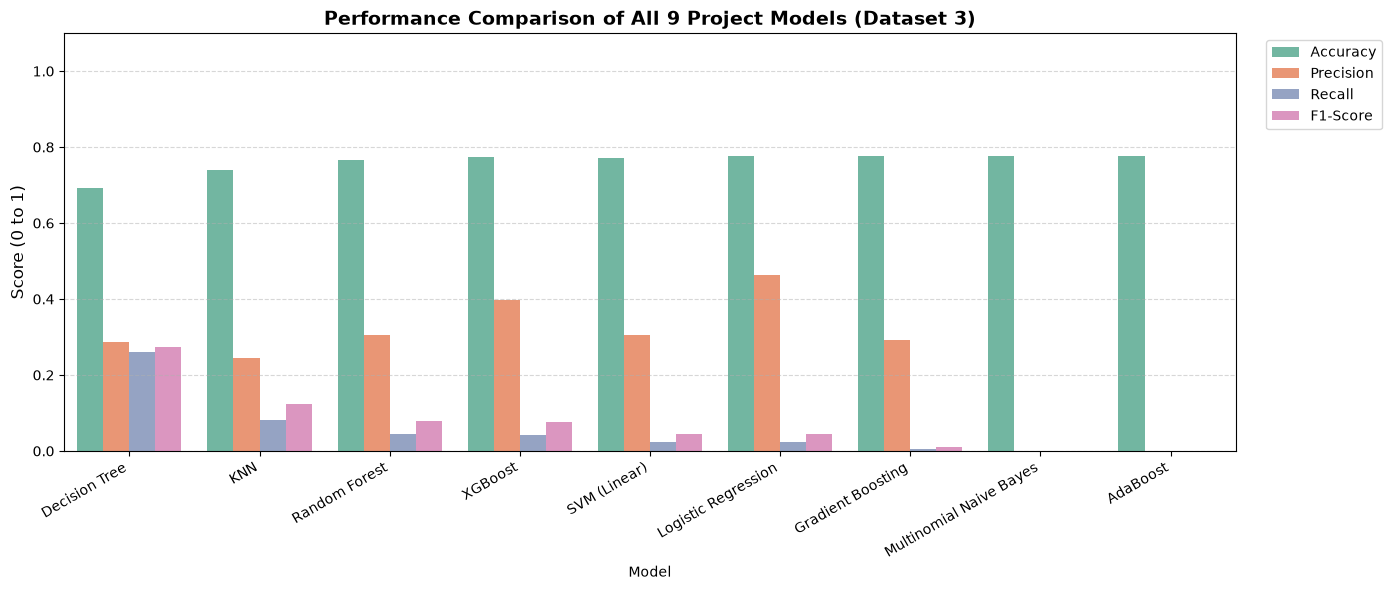

🏆 Best Performing Model on Dataset 3 is: Decision Tree


In [37]:
# Comparison Summary Table
comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Dataset 3: 9 Models Performance Comparison ---")
display(comparison_df)

# Save the Vectorizer
joblib.dump(tfidf, "saved_models/tfidf_vectorizer_dataset3.pkl")

# Comparison Bar Chart
plt.figure(figsize=(14, 6))
df_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison of All 9 Project Models (Dataset 3)", fontsize=14, fontweight='bold')
plt.ylabel("Score (0 to 1)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("saved_models/dataset3_model_comparison.png", dpi=300)
plt.show()

# Print Top Performer
best_model_name = comparison_df.iloc[0]["Model"]
print(f"🏆 Best Performing Model on Dataset 3 is: {best_model_name}")

## Final Model For Dataset3 = Decision Tree